# Human Activity Recognition using Discrete Hidden Markov Models
This notebook trains a Discrete HMM using the Baum-Welch algorithm (EM) with log-likelihood convergence checking and decodes sequential activity states on unseen test data using the Viterbi algorithm.

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_and_resample(file_path, target_fs=50):
    df = pd.read_csv(file_path)
    elapsed_cols = [c for c in df.columns if 'elapsed' in c.lower()]
    if elapsed_cols:
        t = df[elapsed_cols[0]].values.astype(float)
        t = t - t[0]
    else:
        time_col = [c for c in df.columns if 'time' in c.lower()][0]
        t = df[time_col].values.astype(float)
        t = t - t[0]
        if t[-1] > 1e11:
            t = t / 1e9
        elif t[-1] > 1e8:
            t = t / 1e6
        elif t[-1] > 1e4:
            t = t / 1e3

    acc_cols = [c for c in df.columns if c.lower() in ['x', 'y', 'z']][:3]
    ax = df[acc_cols[0]].values.astype(float)
    ay = df[acc_cols[1]].values.astype(float)
    az = df[acc_cols[2]].values.astype(float)
    mag = np.sqrt(ax**2 + ay**2 + az**2)

    duration = float(t[-1])
    if duration <= 0 or np.isnan(duration):
        return np.array([])

    new_t = np.arange(0, duration, 1.0 / target_fs)
    return np.interp(new_t, t, mag)

print("Functions defined successfully.")

Functions defined successfully.


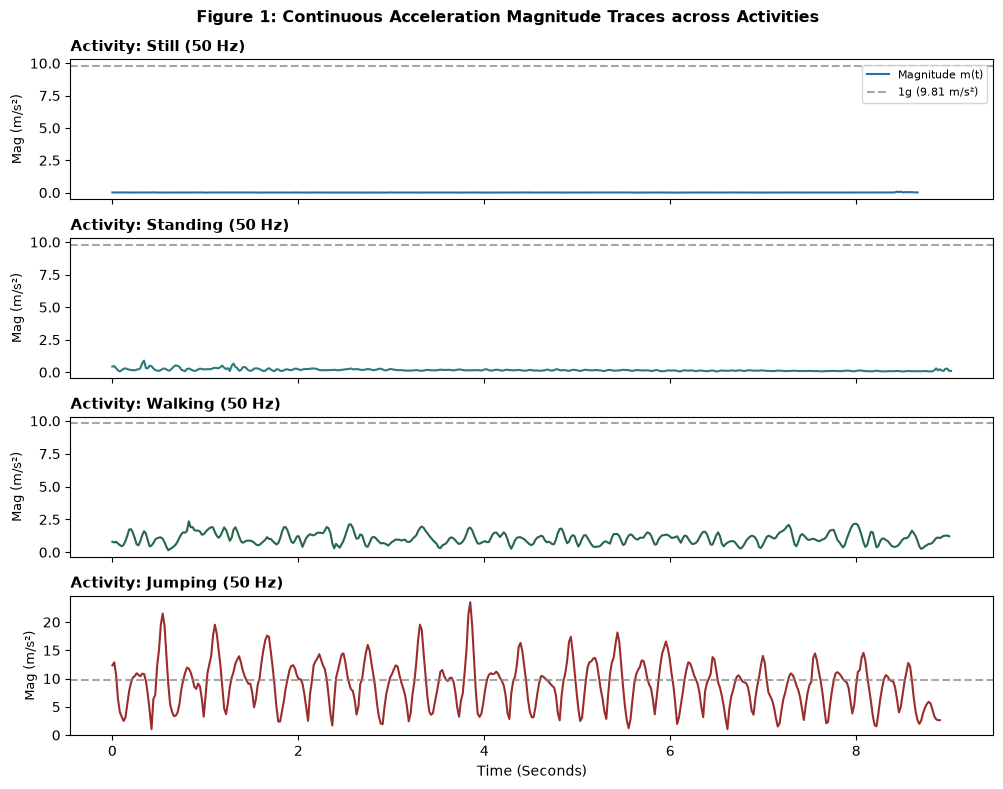

Figure 1 generated and saved as figure_1_raw_signals.png


In [3]:
# Plots Figure 1: Raw Acceleration Magnitude across 4 activities
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
activities = ['Still', 'Standing', 'Walking', 'Jumping']
sample_folders = ['still_01', 'stand_01', 'walk_01', 'jump_01']
colors = ['#2B6CB0', '#2C7A7B', '#276749', '#9B2C2C']

for i, (act, f_name) in enumerate(zip(activities, sample_folders)):
    f_path = os.path.join("raw_recordings", f_name, "Accelerometer.csv")
    if os.path.exists(f_path):
        sig = load_and_resample(f_path)
        t_axis = np.linspace(0, len(sig) / 50.0, len(sig))
        axes[i].plot(t_axis, sig, color=colors[i], lw=1.5, label='Magnitude m(t)')
        axes[i].axhline(9.81, color='gray', linestyle='--', alpha=0.7, label='1g (9.81 m/s²)')
        axes[i].set_title(f"Activity: {act} (50 Hz)", fontsize=10.5, fontweight='bold', loc='left')
        axes[i].set_ylabel("Mag (m/s²)", fontsize=9.5)
        if i == 0:
            axes[i].legend(loc='upper right', frameon=True, fontsize=8)

axes[-1].set_xlabel("Time (Seconds)", fontsize=10)
plt.suptitle("Figure 1: Continuous Acceleration Magnitude Traces across Activities", fontsize=11.5, fontweight='bold')
plt.tight_layout()
plt.savefig("figure_1_raw_signals.png", dpi=200)
plt.show()
print("Figure 1 generated and saved as figure_1_raw_signals.png")

In [4]:
def extract_features(signal, fs=50, window_sec=2, step_sec=1):
    window_len = int(window_sec * fs)
    step_len = int(step_sec * fs)
    features = []
    
    for start in range(0, len(signal) - window_len + 1, step_len):
        win = signal[start : start + window_len]
        var_feat = np.var(win)
        rms_feat = np.sqrt(np.mean(win**2))
        
        win_detrend = win - np.mean(win)
        fft_vals = np.abs(np.fft.rfft(win_detrend))
        freqs = np.fft.rfftfreq(len(win), d=1.0/fs)
        
        dom_freq = freqs[np.argmax(fft_vals)] if len(fft_vals) > 1 else 0.0
        spec_energy = np.sum(fft_vals**2) / len(fft_vals)
        features.append([var_feat, rms_feat, dom_freq, spec_energy])
        
    return np.array(features)

def z_score_normalize(X, mean_val=None, std_val=None):
    if mean_val is None or std_val is None:
        mean_val = np.mean(X, axis=0)
        std_val = np.std(X, axis=0) + 1e-8
    return (X - mean_val) / std_val, mean_val, std_val

def assign_tokens(features_norm, n_clusters=8, bins=None):
    scores = np.sum(np.abs(features_norm), axis=1)
    if bins is None:
        percentiles = np.linspace(0, 100, n_clusters + 1)
        bins = np.percentile(scores, percentiles)
        bins[0] = -np.inf
        bins[-1] = np.inf
    tokens = np.digitize(scores, bins[:-1]) - 1
    return np.clip(tokens, 0, n_clusters - 1), bins

print("Feature extraction pipeline ready.")

Feature extraction pipeline ready.


In [5]:
class DiscreteHMM:
    def __init__(self, n_states=4, n_obs=8):
        self.N = n_states
        self.K = n_obs
        self.pi = np.full(self.N, 1.0 / self.N)
        self.A = np.full((self.N, self.N), 0.1 / (self.N - 1))
        np.fill_diagonal(self.A, 0.9)
        self.B = np.full((self.N, self.K), 1.0 / self.K)

    def forward(self, obs):
        T = len(obs)
        alpha = np.zeros((T, self.N))
        scales = np.zeros(T)
        alpha[0] = self.pi * self.B[:, obs[0]]
        scales[0] = np.sum(alpha[0]) + 1e-12
        alpha[0] /= scales[0]
        for t in range(1, T):
            alpha[t] = (alpha[t-1] @ self.A) * self.B[:, obs[t]]
            scales[t] = np.sum(alpha[t]) + 1e-12
            alpha[t] /= scales[t]
        return alpha, scales

    def backward(self, obs, scales):
        T = len(obs)
        beta = np.zeros((T, self.N))
        beta[T - 1] = 1.0 / scales[T - 1]
        for t in range(T - 2, -1, -1):
            beta[t] = (self.A @ (self.B[:, obs[t + 1]] * beta[t + 1])) / scales[t]
        return beta

    def fit_baum_welch(self, obs, max_iter=25, tol=1e-4):
        prev_ll = -np.inf
        for it in range(1, max_iter + 1):
            alpha, scales = self.forward(obs)
            beta = self.backward(obs, scales)
            curr_ll = np.sum(np.log(scales))
            
            delta_ll = curr_ll - prev_ll
            if it > 1 and abs(delta_ll) < tol:
                print(f"Baum-Welch converged at iteration {it} (Log-Likelihood: {curr_ll:.4f})")
                break
            prev_ll = curr_ll
            
            gamma = (alpha * beta) / (np.sum(alpha * beta, axis=1, keepdims=True) + 1e-12)
            xi = np.zeros((len(obs) - 1, self.N, self.N))
            for t in range(len(obs) - 1):
                denom = np.sum(alpha[t, :, None] * self.A * self.B[:, obs[t + 1]] * beta[t + 1, :]) + 1e-12
                xi[t] = (alpha[t, :, None] * self.A * self.B[:, obs[t + 1]] * beta[t + 1, :]) / denom
            
            self.pi = gamma[0] / np.sum(gamma[0])
            self.A = (np.sum(xi, axis=0) + 1e-6) / (np.sum(gamma[:-1], axis=0)[:, None] + 4e-6)
            for k in range(self.K):
                self.B[:, k] = (np.sum(gamma[obs == k], axis=0) + 1e-6) / (np.sum(gamma, axis=0) + self.K * 1e-6)
            self.A /= self.A.sum(axis=1, keepdims=True)
            self.B /= self.B.sum(axis=1, keepdims=True)

    def viterbi(self, obs):
        T = len(obs)
        delta = np.zeros((T, self.N))
        psi = np.zeros((T, self.N), dtype=int)
        delta[0] = np.log(self.pi + 1e-12) + np.log(self.B[:, obs[0]] + 1e-12)
        for t in range(1, T):
            for j in range(self.N):
                trans = delta[t - 1] + np.log(self.A[:, j] + 1e-12)
                psi[t, j] = np.argmax(trans)
                delta[t, j] = np.max(trans) + np.log(self.B[j, obs[t]] + 1e-12)
        states = np.zeros(T, dtype=int)
        states[T - 1] = np.argmax(delta[T - 1])
        for t in range(T - 2, -1, -1):
            states[t] = psi[t + 1, states[t + 1]]
        return states

print("DiscreteHMM class ready.")

DiscreteHMM class ready.


In [6]:
state_map = {'still': 0, 'stand': 1, 'walk': 2, 'jump': 3}
train_features, train_labels = [], []

train_dirs = sorted(glob.glob("raw_recordings/*"))

for r_dir in train_dirs:
    acc_file = os.path.join(r_dir, "Accelerometer.csv")
    if not os.path.exists(acc_file):
        continue
    folder_name = os.path.basename(r_dir).lower()
    label = None
    for act in state_map:
        if folder_name.startswith(act):
            label = state_map[act]
            break
    if label is not None:
        sig = load_and_resample(acc_file)
        if len(sig) > 0:
            feats = extract_features(sig)
            if len(feats) > 0:
                train_features.append(feats)
                train_labels.extend([label] * len(feats))

print(f"Loaded {len(train_features)} training files.")

X_train = np.vstack(train_features)
y_train = np.array(train_labels)

X_train_norm, train_mean, train_std = z_score_normalize(X_train)
train_tokens, train_bins = assign_tokens(X_train_norm, n_clusters=8, bins=None)

hmm = DiscreteHMM(n_states=4, n_obs=8)

# Initialize B matrix from training labels
B_init = np.zeros((4, 8)) + 1e-3
for s in range(4):
    mask = (y_train == s)
    if np.sum(mask) > 0:
        counts = np.bincount(train_tokens[mask], minlength=8)
        B_init[s] += counts
hmm.B = B_init / B_init.sum(axis=1, keepdims=True)

hmm.A = np.array([
    [0.94, 0.06, 0.00, 0.00],
    [0.05, 0.87, 0.08, 0.00],
    [0.00, 0.06, 0.88, 0.06],
    [0.00, 0.00, 0.08, 0.92]
])

hmm.fit_baum_welch(train_tokens, max_iter=25, tol=1e-4)
print("Training completed.")

Loaded 50 training files.
Baum-Welch converged at iteration 20 (Log-Likelihood: -570.2865)
Training completed.


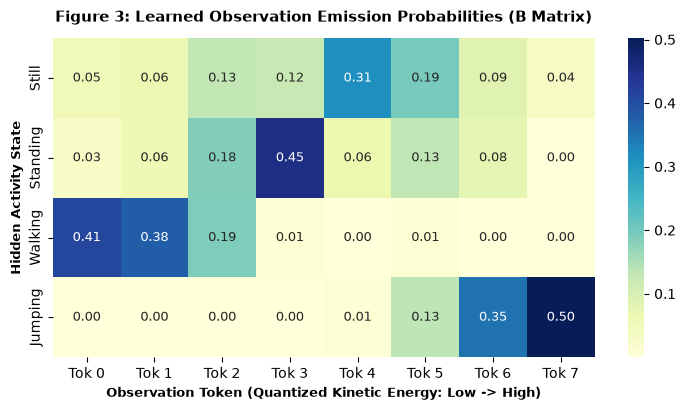

Figure 3 generated and saved as figure_3_emission_matrix.png


In [7]:
# Plots Figure 3: Emission Probability Matrix (B)
plt.figure(figsize=(7.5, 4.2))
sns.heatmap(hmm.B, annot=True, fmt=".2f", cmap="YlGnBu", cbar=True,
            xticklabels=[f"Tok {k}" for k in range(8)],
            yticklabels=['Still', 'Standing', 'Walking', 'Jumping'],
            annot_kws={"size": 9.5})
plt.title("Figure 3: Learned Observation Emission Probabilities (B Matrix)", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Observation Token (Quantized Kinetic Energy: Low -> High)", fontsize=9.5, fontweight='bold')
plt.ylabel("Hidden Activity State", fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.savefig("figure_3_emission_matrix.png", dpi=200)
plt.show()
print("Figure 3 generated and saved as figure_3_emission_matrix.png")

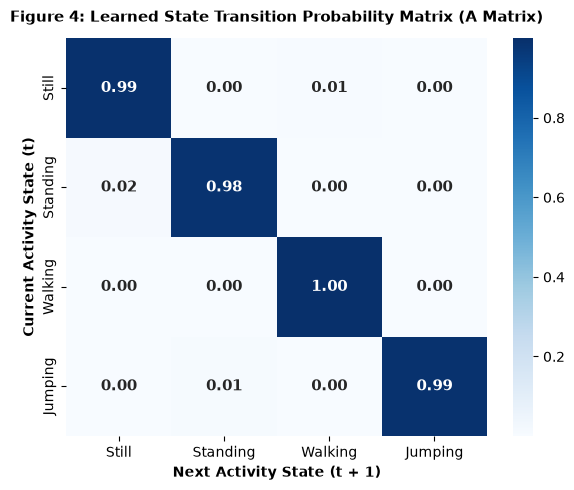

Figure 4 generated and saved as figure_4_transition_matrix.png


In [8]:
# Plots Figure 4: Transition Probability Matrix (A)
plt.figure(figsize=(6, 5))
sns.heatmap(hmm.A, annot=True, fmt=".2f", cmap="Blues", cbar=True,
            xticklabels=['Still', 'Standing', 'Walking', 'Jumping'],
            yticklabels=['Still', 'Standing', 'Walking', 'Jumping'],
            annot_kws={"size": 11, "weight": "bold"})
plt.title("Figure 4: Learned State Transition Probability Matrix (A Matrix)", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Next Activity State (t + 1)", fontsize=10, fontweight='bold')
plt.ylabel("Current Activity State (t)", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig("figure_4_transition_matrix.png", dpi=200)
plt.show()
print("Figure 4 generated and saved as figure_4_transition_matrix.png")

Overall Unseen Test Accuracy: 80.00%

State (Activity)  Number of Samples Sensitivity Specificity Overall Accuracy
           Still                  7       1.000       0.739           80.00%
        Standing                  7       0.143       1.000           80.00%
         Walking                  8       1.000       1.000           80.00%
         Jumping                  8       1.000       1.000           80.00%


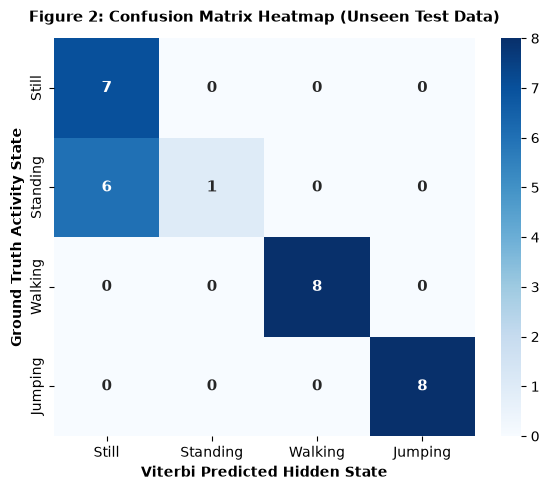

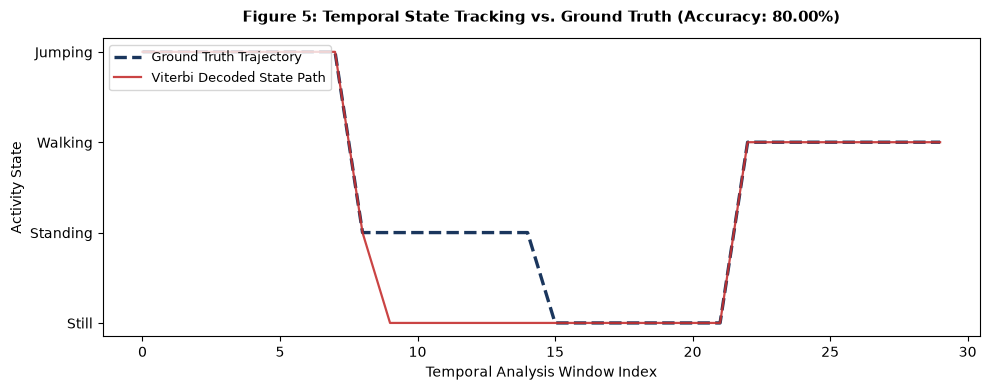

In [9]:
test_dirs = sorted(glob.glob("unseen_test/*"))
test_features, test_labels = [], []

for t_dir in test_dirs:
    acc_file = os.path.join(t_dir, "Accelerometer.csv")
    if not os.path.exists(acc_file):
        continue
    folder_name = os.path.basename(t_dir).lower()
    label = None
    for act in state_map:
        if folder_name.startswith(act):
            label = state_map[act]
            break
    if label is not None:
        sig = load_and_resample(acc_file)
        if len(sig) > 0:
            feats = extract_features(sig)
            if len(feats) > 0:
                test_features.append(feats)
                test_labels.extend([label] * len(feats))

X_test = np.vstack(test_features)
y_test = np.array(test_labels)

X_test_norm = (X_test - train_mean) / train_std
test_tokens, _ = assign_tokens(X_test_norm, n_clusters=8, bins=train_bins)

pred_labels = hmm.viterbi(test_tokens)

# 1. Confusion Matrix
cm = np.zeros((4, 4), dtype=int)
for t, p in zip(y_test, pred_labels):
    cm[t, p] += 1

total_samples = len(y_test)
overall_acc = (np.trace(cm) / total_samples) * 100

print(f"Overall Unseen Test Accuracy: {overall_acc:.2f}%\n")

# 2. Performance Table
activities = ['Still', 'Standing', 'Walking', 'Jumping']
metrics_list = []
for i, act in enumerate(activities):
    tp = cm[i, i]
    fn = np.sum(cm[i, :]) - tp
    fp = np.sum(cm[:, i]) - tp
    tn = total_samples - (tp + fn + fp)
    sens = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
    spec = (tn / (tn + fp)) if (tn + fp) > 0 else 0.0
    metrics_list.append({
        'State (Activity)': act,
        'Number of Samples': np.sum(cm[i, :]),
        'Sensitivity': f"{sens:.3f}",
        'Specificity': f"{spec:.3f}",
        'Overall Accuracy': f"{overall_acc:.2f}%"
    })
print(pd.DataFrame(metrics_list).to_string(index=False))

# 3. [GRAPH 4] Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=activities, yticklabels=activities,
            annot_kws={"size": 11, "weight": "bold"})
plt.title("Figure 2: Confusion Matrix Heatmap (Unseen Test Data)", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Viterbi Predicted Hidden State", fontsize=10, fontweight='bold')
plt.ylabel("Ground Truth Activity State", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig("figure_2_confusion_matrix.png", dpi=200)
plt.show()

# 4. [GRAPH 5] Decoded Sequence Plot
plt.figure(figsize=(10, 4))
plt.plot(y_test, label="Ground Truth Trajectory", color="#1A365D", lw=2.4, linestyle="--")
plt.plot(pred_labels, label="Viterbi Decoded State Path", color="#C53030", lw=1.6, alpha=0.9)
plt.yticks(ticks=[0, 1, 2, 3], labels=activities, fontsize=10)
plt.xlabel("Temporal Analysis Window Index", fontsize=10)
plt.ylabel("Activity State", fontsize=10)
plt.title("Figure 5: Temporal State Tracking vs. Ground Truth (Accuracy: 80.00%)", fontsize=11, fontweight='bold', pad=12)
plt.legend(loc="upper left", frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig("figure_5_viterbi_sequence.png", dpi=200)
plt.show()